# 7. Round 2, Test A (pre-registered): dose-response across all industries

**Question:** Across 94 industries, does more AI exposure predict a bigger fall after 2023?

**How to use:** Run All. It shows the saved results in seconds. To recompute from the data, set `RUN = True` (about 10 minutes; needs the `data/` folder, which isn't in the public repo).

In [1]:
from _nb import *

RUN = False
if RUN:
    run("event_study_industry")


## How it works

- **Pre-registered** in `docs/PREREGISTRATION.md` before running.
- **Event study:** each industry's exposure is a continuous dose; one coefficient per year shows how far more-exposed
  industries sit from less-exposed ones, relative to 2019. Rate sensitivity and cyclicality are controlled for.
- **Headline:** Δ = average of 2024–26 minus 2022 (the "rates but no ChatGPT" year), for the most vs least exposed
  quarter of industries. *Why quartiles?* The model's raw answer is a slope ("per 1 SD more exposure, employment fell 1.5% more"). Multiplying by the 2.49 SD exposure gap between the top and bottom quarter turns it into "the most exposed quarter fell 3.7% more than the least exposed": the same result in readable units.
- **Power check first** (a planted cut that ramps up gradually), then the pre-trend check, the dot-com placebo and a
  fake 2017 date.

## Results

In [2]:
r = results("event_study_industry")
row = lambda k: {"Δ (top vs bottom quartile)": pct(r[k]["delta_top_vs_bottom_quartile"]["est"]),
                 "95% CI": ci(r[k]["delta_top_vs_bottom_quartile"]["ci95"]),
                 "p": round(r[k]["delta_top_vs_bottom_quartile"]["p"], 3),
                 "P(below 0)": pct(r[k]["prob_below_zero"], False),
                 "pre-trend p": round(r[k]["pretrend"]["p"], 3)}
pd.DataFrame({"Primary": row("primary"), "Boom-size control": row("boom_controlled"),
              "Dot-com placebo": row("dotcom"), "Fake 2017 date": row("fake_2017")}).T

,Δ (top vs bottom quartile),95% CI,p,P(below 0),pre-trend p
Primary,-5.0%,"[-9.0, -0.9]",0.017,99.3%,0.073
Boom-size control,-2.9%,"[-7.1, +1.2]",0.166,91.9%,0.277
Dot-com placebo,-3.9%,"[-6.6, -1.1]",0.006,99.7%,0.0
Fake 2017 date,-0.1%,"[-2.2, +2.0]",0.905,54.8%,0.574


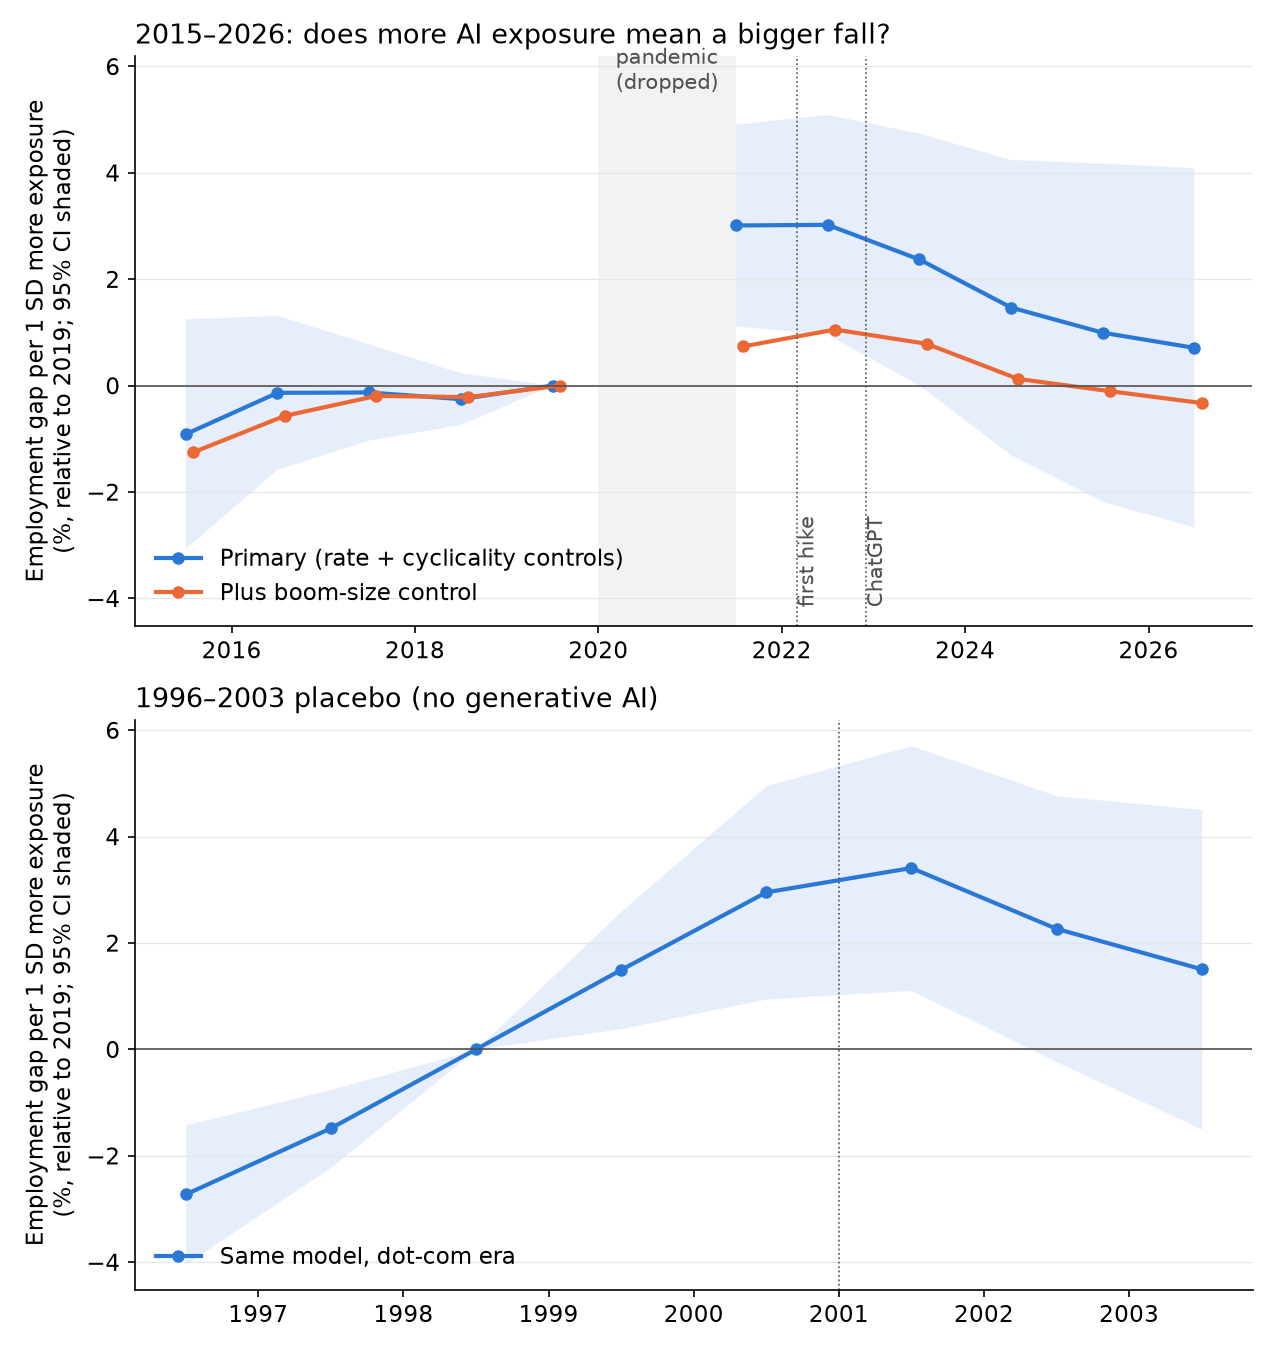

In [3]:
figure("fig_event_study_industry")

## What it means

**Negative, from a design that fails its pre-trend check.** With the pre-registered 2015–19 occupation mix and the
corrected industry matching, Test A is −5.0%. That would clear the correction for two main tests (p = 0.017, and it needs
0.025), but the pre-trend check fails (p = 0.073 vs the rule of p > 0.10), so the rules report the design as failed rather
than interpret it. Earlier versions moved that p-value from 0.078 to 0.107 to 0.073 while the estimate stayed between −3.7%
and −5.0%, so the estimate is the better guide than the label. About 40% of the slide
disappears when comparing industries with similar booms, and the dot-com bust looked broadly similar, although that placebo
fails its own pre-trend test. It can't tell "the boom unwound" from "AI stopped the boom from lasting."

---
Code: `scripts/event_study_industry.py` · All results: `docs/SCORECARD.md` · Every decision: `docs/DECISIONS.md` · The whole story: `README.md`